# Machine-Learning Ground-Motion Model (NGA-West2, California)

Random-forest regression of Fourier amplitude spectra (FAS) at five frequencies (0.5–4.6 Hz) from magnitude, rupture distance, Vs30 and event/station coordinates.

> **Data:** the input CSV is not included in this repository. Place it in Google Drive (or locally) and edit the path in the data-loading cell.

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd

# Replace 'path/to/your/file.csv' with the actual path from your Google Drive
file_path = '/content/drive/My Drive/Colab Notebooks/data/NGA2West_FAS_CA.csv'
df_FAS = pd.read_csv(file_path)
file_path1 = '/content/drive/My Drive/Colab Notebooks/data/NGA2West_FAS_CA_residual.csv'
df_resi = pd.read_csv(file_path1)

# Display the first few rows of the DataFrame to verify
df_FAS.head()

,rsn,eqid,ssn,region,mag,Rrup,Vs30,Z1.0,Ztor,SOF,...,freq19.952621,freq20.417380,freq20.892960,freq21.379620,freq21.877611,freq22.387210,freq22.908672,freq23.442283,freq23.988321,sub_region
0,28,25,132,1,6.19,17.64,359.03,0.08,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
1,30,25,128,1,6.19,9.58,236.59,0.08,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
2,31,25,129,1,6.19,12.90,256.82,0.08,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
3,32,25,147,1,6.19,63.34,493.50,0.04,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
4,33,25,162,1,6.19,15.96,527.92,0.04,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1


In [ ]:

# Manually selected frequency columns
selected_freq_cols = [
    'freq0.501187',
    'freq1.000000',
    'freq2.041738',
    'freq3.019952',
    'freq4.570881',
]

# Extract frequency values
selected_freq_values = [float(col.replace('freq', '')) for col in selected_freq_cols]
selected_freq_values


[0.501187, 1.0, 2.041738, 3.019952, 4.570881]

In [ ]:
# Input features
X = df_FAS[['mag', 'Rrup', 'Vs30', 'eqUTMx', 'eqUTMy', 'staUTMx', 'staUTMy']].copy()
X['log_Rrup'] = np.log10(X['Rrup'] + 1)
X['log_Vs30'] = np.log10(X['Vs30'])
X['mag_squared'] = X['mag'] ** 2

# Target frequencies
Y = df_FAS[selected_freq_cols].copy()

# Handle missing values
X = X.fillna(X.median())
Y = Y.fillna(Y.median())


In [ ]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)


In [ ]:

# Normalize
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [ ]:
models = {}
predictions_test = {}

for freq_col in selected_freq_cols:
    model = RandomForestRegressor(n_estimators=100, max_depth=15, random_state=42, n_jobs=-1)
    model.fit(X_train_scaled, Y_train[freq_col])
    models[freq_col] = model
    predictions_test[freq_col] = model.predict(X_test_scaled)

print("Training complete!")


Training complete!


In [ ]:
print("\n" + "="*60)
print("MODEL PERFORMANCE")
print("="*60)
results = []
for freq_col, freq_val in zip(selected_freq_cols, selected_freq_values):
    r2 = r2_score(Y_test[freq_col], predictions_test[freq_col])
    rmse = np.sqrt(mean_squared_error(Y_test[freq_col], predictions_test[freq_col]))
    results.append({'Frequency (Hz)': freq_val, 'R²': r2, 'RMSE': rmse})
    print(f"{freq_val:6.3f} Hz: R² = {r2:.3f}, RMSE = {rmse:.4f}")

results_df = pd.DataFrame(results)
print(f"\nAverage R²: {results_df['R²'].mean():.3f}")



MODEL PERFORMANCE
 0.501 Hz: R² = 0.649, RMSE = 0.0095
 1.000 Hz: R² = 0.696, RMSE = 0.0101
 2.042 Hz: R² = 0.710, RMSE = 0.0104
 3.020 Hz: R² = 0.751, RMSE = 0.0080
 4.571 Hz: R² = 0.660, RMSE = 0.0080

Average R²: 0.693



COMPLETE!

Outputs saved to /mnt/user-data/outputs/:
  - performance.csv
  - fig1_predicted_vs_actual.png
  - fig2_magnitude_variation.png
  - fig3_distance_variation.png
  - fig4_vs30_variation.png
  - fig5_frequency_correlation.png


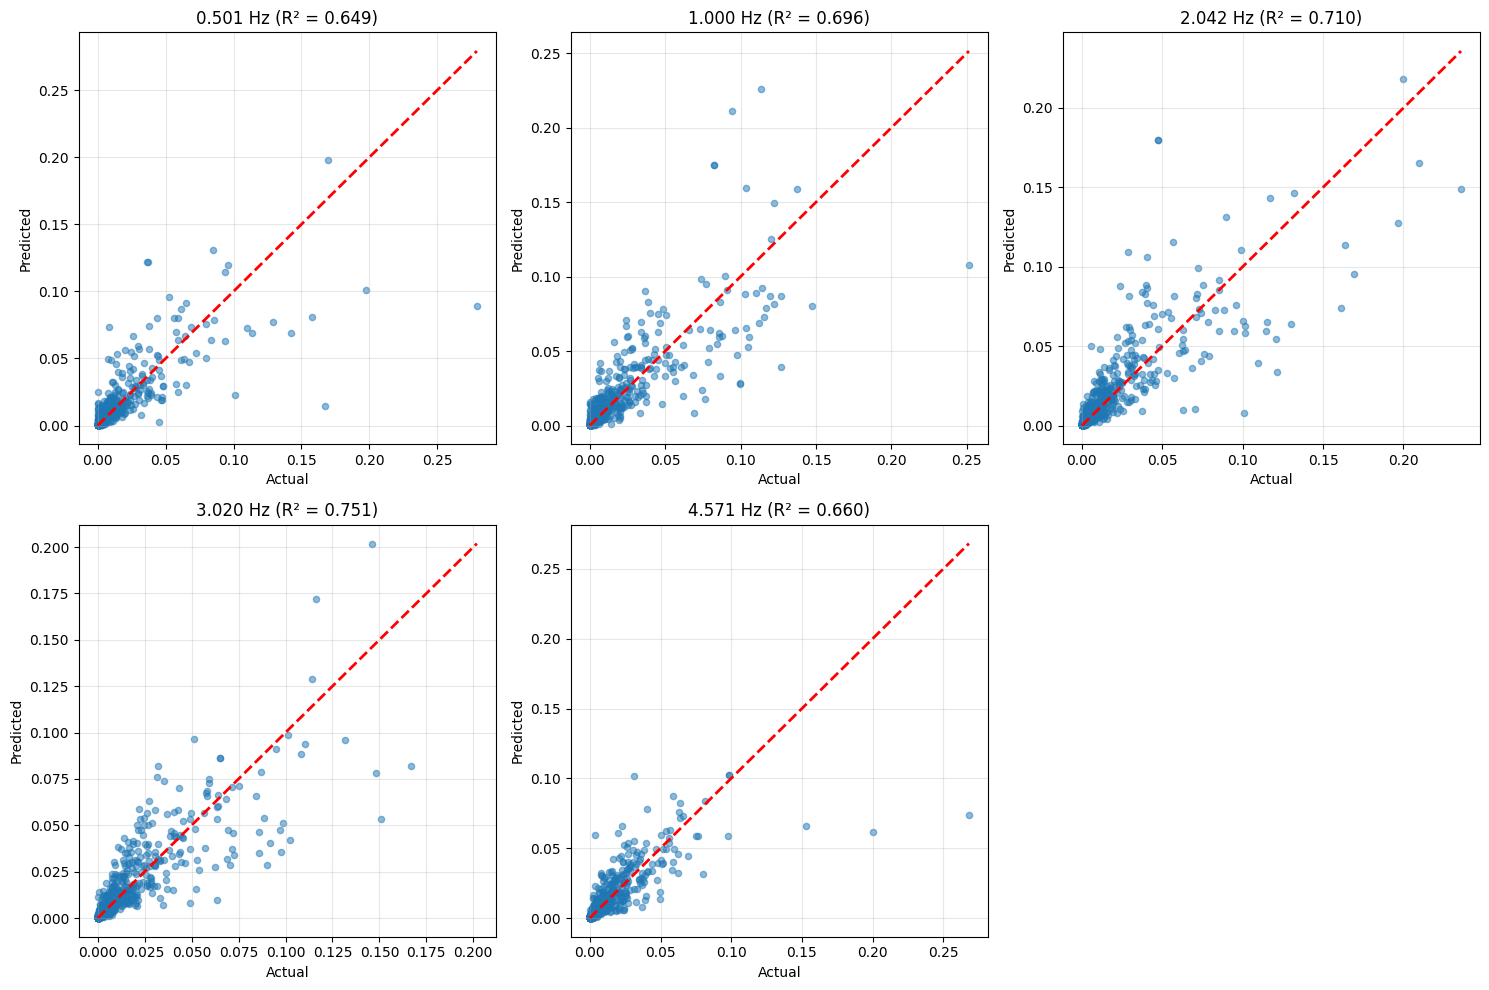

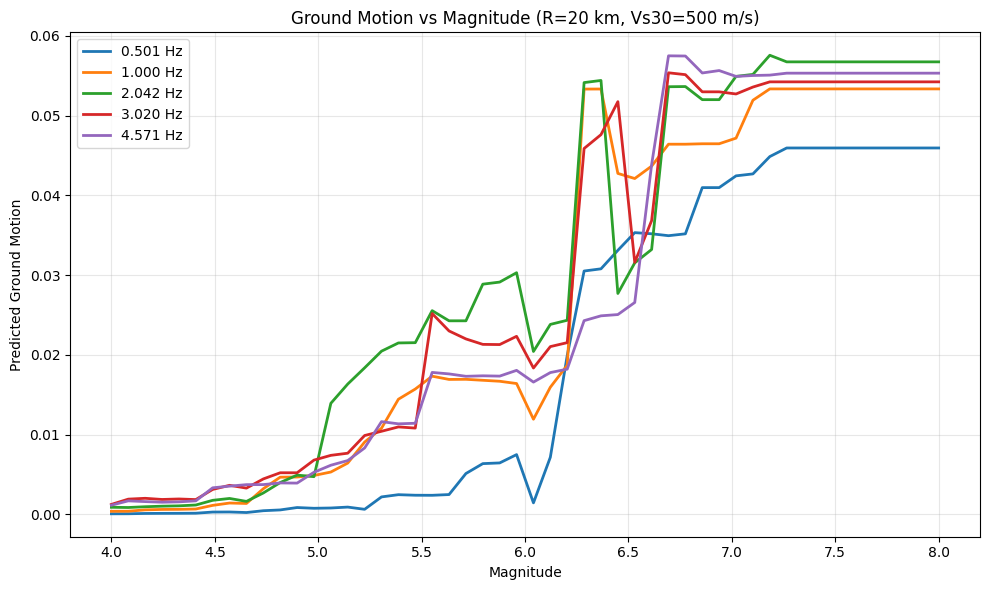

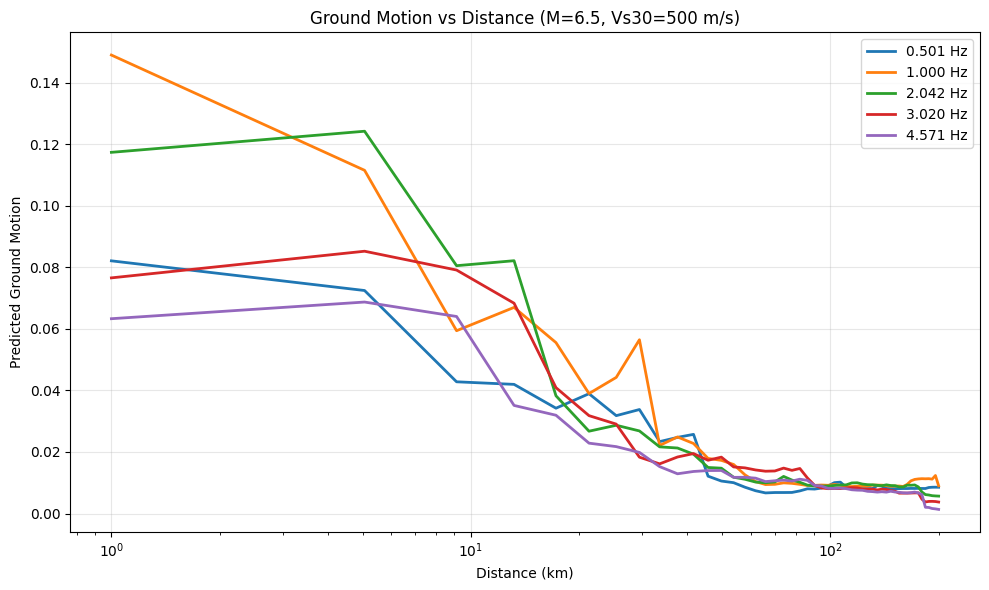

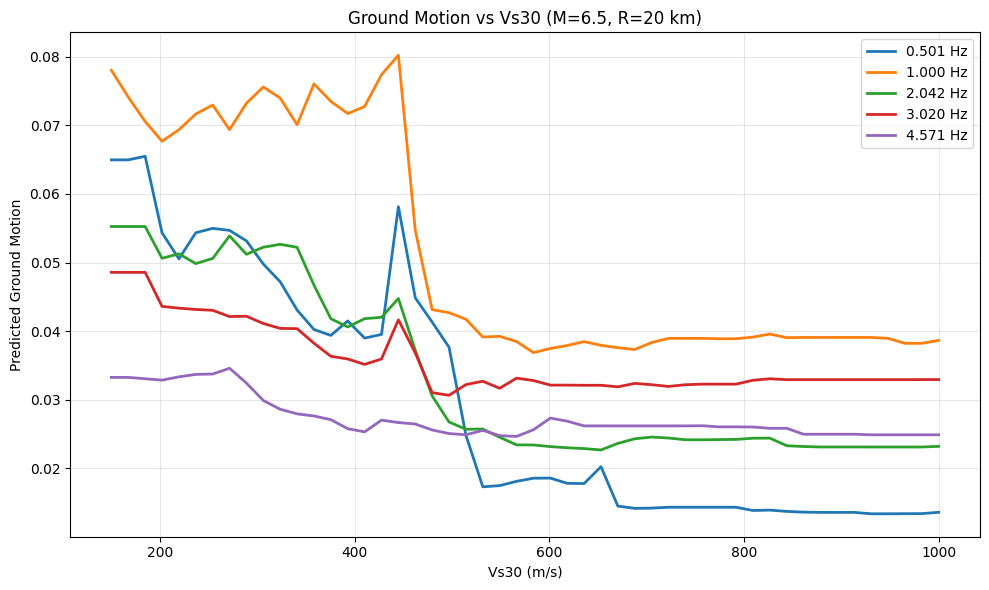

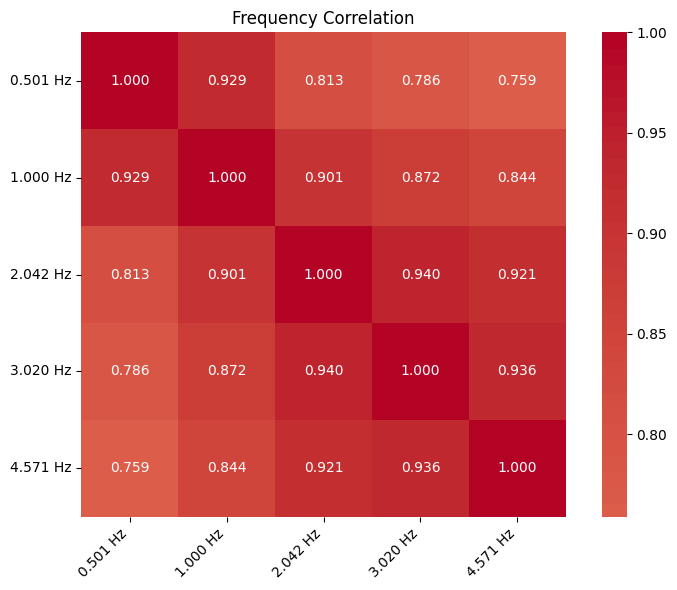

In [ ]:

# Figure 1: Predicted vs Actual
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()
for i, (freq_col, freq_val) in enumerate(zip(selected_freq_cols, selected_freq_values)):
    r2 = r2_score(Y_test[freq_col], predictions_test[freq_col])
    axes[i].scatter(Y_test[freq_col], predictions_test[freq_col], alpha=0.5, s=20)
    lims = [min(Y_test[freq_col].min(), predictions_test[freq_col].min()),
            max(Y_test[freq_col].max(), predictions_test[freq_col].max())]
    axes[i].plot(lims, lims, 'r--', lw=2)
    axes[i].set_xlabel('Actual')
    axes[i].set_ylabel('Predicted')
    axes[i].set_title(f'{freq_val:.3f} Hz (R² = {r2:.3f})')
    axes[i].grid(True, alpha=0.3)
axes[-1].remove()
plt.tight_layout()
# plt.savefig('/mnt/user-data/outputs/fig1_predicted_vs_actual.png', dpi=300)

# Figure 2: Magnitude Variation
magnitudes = np.linspace(4.0, 8.0, 50)
fig, ax = plt.subplots(figsize=(10, 6))
for freq_col, freq_val in zip(selected_freq_cols, selected_freq_values):
    preds = []
    for mag in magnitudes:
        scenario = pd.DataFrame([{
            'mag': mag, 'Rrup': 20.0, 'Vs30': 500.0,
            'eqUTMx': X['eqUTMx'].median(), 'eqUTMy': X['eqUTMy'].median(),
            'staUTMx': X['staUTMx'].median(), 'staUTMy': X['staUTMy'].median(),
            'log_Rrup': np.log10(21.0), 'log_Vs30': np.log10(500.0),
            'mag_squared': mag**2
        }])
        pred = models[freq_col].predict(scaler.transform(scenario))[0]
        preds.append(pred)
    ax.plot(magnitudes, preds, linewidth=2, label=f'{freq_val:.3f} Hz')
ax.set_xlabel('Magnitude')
ax.set_ylabel('Predicted Ground Motion')
ax.set_title('Ground Motion vs Magnitude (R=20 km, Vs30=500 m/s)')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
# plt.savefig('/mnt/user-data/outputs/fig2_magnitude_variation.png', dpi=300)

# Figure 3: Distance Variation
distances = np.linspace(1, 200, 50)
fig, ax = plt.subplots(figsize=(10, 6))
for freq_col, freq_val in zip(selected_freq_cols, selected_freq_values):
    preds = []
    for dist in distances:
        scenario = pd.DataFrame([{
            'mag': 6.5, 'Rrup': dist, 'Vs30': 500.0,
            'eqUTMx': X['eqUTMx'].median(), 'eqUTMy': X['eqUTMy'].median(),
            'staUTMx': X['staUTMx'].median(), 'staUTMy': X['staUTMy'].median(),
            'log_Rrup': np.log10(dist + 1), 'log_Vs30': np.log10(500.0),
            'mag_squared': 6.5**2
        }])
        pred = models[freq_col].predict(scaler.transform(scenario))[0]
        preds.append(pred)
    ax.plot(distances, preds, linewidth=2, label=f'{freq_val:.3f} Hz')
ax.set_xlabel('Distance (km)')
ax.set_ylabel('Predicted Ground Motion')
ax.set_title('Ground Motion vs Distance (M=6.5, Vs30=500 m/s)')
ax.legend()
ax.grid(True, alpha=0.3)
ax.set_xscale('log')
plt.tight_layout()
# plt.savefig('/mnt/user-data/outputs/fig3_distance_variation.png', dpi=300)

# Figure 4: Vs30 Variation
vs30_values = np.linspace(150, 1000, 50)
fig, ax = plt.subplots(figsize=(10, 6))
for freq_col, freq_val in zip(selected_freq_cols, selected_freq_values):
    preds = []
    for vs30 in vs30_values:
        scenario = pd.DataFrame([{
            'mag': 6.5, 'Rrup': 20.0, 'Vs30': vs30,
            'eqUTMx': X['eqUTMx'].median(), 'eqUTMy': X['eqUTMy'].median(),
            'staUTMx': X['staUTMx'].median(), 'staUTMy': X['staUTMy'].median(),
            'log_Rrup': np.log10(21.0), 'log_Vs30': np.log10(vs30),
            'mag_squared': 6.5**2
        }])
        pred = models[freq_col].predict(scaler.transform(scenario))[0]
        preds.append(pred)
    ax.plot(vs30_values, preds, linewidth=2, label=f'{freq_val:.3f} Hz')
ax.set_xlabel('Vs30 (m/s)')
ax.set_ylabel('Predicted Ground Motion')
ax.set_title('Ground Motion vs Vs30 (M=6.5, R=20 km)')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
# plt.savefig('/mnt/user-data/outputs/fig4_vs30_variation.png', dpi=300)

# Figure 5: Frequency Correlation
pred_df = pd.DataFrame(predictions_test)
corr = pred_df.corr()
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.3f', cmap='coolwarm', center=0, square=True, ax=ax)
freq_labels = [f'{val:.3f} Hz' for val in selected_freq_values]
ax.set_xticklabels(freq_labels, rotation=45, ha='right')
ax.set_yticklabels(freq_labels, rotation=0)
ax.set_title('Frequency Correlation')
plt.tight_layout()
# plt.savefig('/mnt/user-data/outputs/fig5_frequency_correlation.png', dpi=300)

print("\n" + "="*60)
print("COMPLETE!")
print("="*60)
print("\nOutputs saved to /mnt/user-data/outputs/:")
print("  - performance.csv")
print("  - fig1_predicted_vs_actual.png")
print("  - fig2_magnitude_variation.png")
print("  - fig3_distance_variation.png")
print("  - fig4_vs30_variation.png")
print("  - fig5_frequency_correlation.png")
